# Lab 10: Implementation of Q-Learning Algorithm for Grid World

## 1. Aim and Objectives
- **Aim**: Implement the Q-Learning algorithm, a model-free reinforcement learning approach, to train an agent to navigate a custom Grid World environment.
- **Objectives**:
  1. Understand RL components: states, actions, rewards, Q-values, learning rate, and discount factor.
  2. Create a Grid World environment containing a starting state, obstacles (blocked cells), and a goal state.
  3. Train a reinforcement learning agent using the epsilon-greedy exploration-exploitation strategy.
  4. Evaluate the agent's performance using metrics such as cumulative rewards, training steps, and success rate.
  5. Display and analyze the final learned Q-table, optimal policy paths, and visualize the results.

## 2. Import Libraries

We import essential libraries for numeric computation, table manipulation, plotting, and random number generation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random

# Set random seeds for reproducibility
np.random.seed(42)
random.seed(42)

print("Libraries successfully imported!")

Libraries successfully imported!


## 3. Theoretical Background

### Core Reinforcement Learning Concepts
- **Reinforcement Learning (RL)**: A subfield of Machine Learning where an agent learns to make decisions by performing actions in an environment to maximize some notion of cumulative reward.
- **Agent and Environment**: The *Agent* is the decision-maker (our robot learner). The *Environment* is everything the agent interacts with (our Grid World).
- **State (S)**: A representation of the current situation or position of the agent.
- **Action (A)**: Decisions or moves the agent can make in a state (e.g., Up, Down, Left, Right).
- **Reward (R)**: Feedback from the environment evaluating the agent's action (positive for progress/success, negative for penalties).
- **Q-value (Quality value)**: The expected cumulative future reward of taking a specific action in a specific state.
- **Learning Rate ($\alpha$)**: Determines to what extent newly acquired information overrides old information (0 = learns nothing new, 1 = considers only the most recent information).
- **Discount Factor ($\gamma$)**: Determines the importance of future rewards (0 = short-sighted, close to 1 = far-sighted).
- **Exploration vs. Exploitation**: *Exploration* is trying new actions to gather more information. *Exploitation* is choosing the best-known actions to maximize rewards.
- **Epsilon-Greedy Policy**: A strategy that selects a random action with probability $\epsilon$ (exploration) and the action with the highest Q-value with probability $1 - \epsilon$ (exploitation).
- **Markov Decision Process (MDP)**: A mathematical framework for modeling decision-making where outcomes are partly random and partly under the control of a decision-maker.

### The Q-Learning Update Equation
Q-Learning is an off-policy temporal difference algorithm. The fundamental update equation is:

$$Q(s, a) \leftarrow Q(s, a) + \alpha \left[ r + \gamma \max_{a'} Q(s', a') - Q(s, a) \right]$$

**Equation Term Explanations**:
- $Q(s, a)$: Current expected future reward for taking action $a$ in state $s$.
- $\alpha$: Learning rate (step-size parameter).
- $r$: Immediate reward received after transitioning from state $s$ to state $s'$ by action $a$.
- $\gamma$: Discount factor.
- $\max_{a'} Q(s', a')$: The maximum predicted Q-value for any action $a'$ in the next state $s'$.
- Temporal Difference Error ($r + \gamma \max_{a'} Q(s', a') - Q(s, a)$): The difference between our target estimate and our current estimate.

## 4. Create the Grid World Environment

Here we implement a $5 \times 5$ Grid World environment using a customized class.
- **Start State**: (0,0)
- **Goal State**: (4,4)
- **Obstacles**: Blocked cells at (1,1), (2,2), (3,3) and (3,1).
- **Actions**: 0 = Up, 1 = Down, 2 = Left, 3 = Right
- **Rewards**:
  - Goal State: +10
  - Obstacle hit: -5
  - Step penalty (standard moves): -1 to encourage shorter paths

In [2]:
class GridWorld:
    def __init__(self, size=5):
        self.size = size
        self.start = (0, 0)
        self.goal = (4, 4)
        # Define obstacle positions
        self.obstacles = [(1, 1), (2, 2), (3, 3), (3, 1)]
        self.state = self.start

        # Action Mapping
        self.action_space = [0, 1, 2, 3] # 0: Up, 1: Down, 2: Left, 3: Right
        self.action_names = {0: 'Up', 1: 'Down', 2: 'Left', 3: 'Right'}

    def reset(self):
        self.state = self.start
        return self.state

    def step(self, action):
        r, c = self.state

        # Calculate potential next state based on action
        if action == 0:    # Up
            next_r, next_c = r - 1, c
        elif action == 1:  # Down
            next_r, next_c = r + 1, c
        elif action == 2:  # Left
            next_r, next_c = r, c - 1
        elif action == 3:  # Right
            next_r, next_c = r, c + 1
        else:
            raise ValueError("Invalid Action!")

        # Boundary checks: If agent tries to walk out of grid
        if next_r < 0 or next_r >= self.size or next_c < 0 or next_c >= self.size:
            # Stays in the same state, receives out-of-bounds penalty
            reward = -1.5
            next_state = self.state
            done = False
            return next_state, reward, done

        # Obstacle check
        if (next_r, next_c) in self.obstacles:
            # Agent is blocked and cannot move, receives strong negative penalty
            reward = -5.0
            next_state = self.state
            done = False
            return next_state, reward, done

        # Success check
        if (next_r, next_c) == self.goal:
            reward = 10.0
            next_state = (next_r, next_c)
            done = True
            return next_state, reward, done

        # Normal state movement step
        reward = -1.0
        next_state = (next_r, next_c)
        done = False

        self.state = next_state
        return next_state, reward, done

env = GridWorld()
print("Grid World Environment initial state reset:", env.reset())

Grid World Environment initial state reset: (0, 0)


## 5. Initialize the Q-Table

The Q-Table is initialized to hold values for each possible state-action combination. In a $5 \times 5$ grid, we have $25$ states. We map grid coordinates $(r, c)$ to flat indices as $r \times 5 + c$.

In [3]:
num_states = env.size * env.size
num_actions = len(env.action_space)

# Initialize Q-table to zeros
q_table = np.zeros((num_states, num_actions))

def get_state_idx(coords, size=5):
    r, c = coords
    return r * size + c

def get_coords(state_idx, size=5):
    return (state_idx // size, state_idx % size)

print(f"Q-Table initialized with shape {q_table.shape} representing {num_states} states and {num_actions} actions.")

Q-Table initialized with shape (25, 4) representing 25 states and 4 actions.


## 6. Implement Q-Learning

We train the Q-Learning agent with the given parameters and decay schedule. An epsilon-greedy strategy handles exploration and exploitation.

In [4]:
# Training Parameters
alpha = 0.1
gamma = 0.9
epsilon = 1.0
min_epsilon = 0.01
decay_rate = 0.995
episodes = 3000
max_steps = 100

# Data collection structures
training_data = []

for ep in range(episodes):
    state = env.reset()
    total_reward = 0
    steps = 0
    done = False

    while not done and steps < max_steps:
        state_idx = get_state_idx(state)

        # Epsilon-greedy action selection
        if random.uniform(0, 1) < epsilon:
            action = random.choice(env.action_space) # Explore
        else:
            action = np.argmax(q_table[state_idx])    # Exploit

        # Environment step
        next_state, reward, done = env.step(action)
        next_state_idx = get_state_idx(next_state)

        # Q-Learning update calculation
        best_next_q = np.max(q_table[next_state_idx])
        q_table[state_idx, action] = q_table[state_idx, action] + alpha * (
            reward + gamma * best_next_q - q_table[state_idx, action]
        )

        state = next_state
        total_reward += reward
        steps += 1

    # Decay epsilon
    epsilon = max(min_epsilon, epsilon * decay_rate)

    # Track metrics
    training_data.append({
        'Episode': ep + 1,
        'Reward': total_reward,
        'Steps': steps,
        'GoalReached': done,
        'Epsilon': epsilon
    })

df_training = pd.DataFrame(training_data)
print("Training Complete! First 5 and last 5 performance logs shown below:")
display(df_training.head())
display(df_training.tail())

Training Complete! First 5 and last 5 performance logs shown below:


,Episode,Reward,Steps,GoalReached,Epsilon
0,1,-189.5,90,True,0.995000
1,2,-196.5,100,False,0.990025
2,3,-197.5,100,False,0.985075
3,4,-36.5,23,True,0.980150
4,5,-206.0,100,False,0.975249


,Episode,Reward,Steps,GoalReached,Epsilon
2995,2996,3.0,8,True,0.01
2996,2997,3.0,8,True,0.01
2997,2998,1.5,9,True,0.01
2998,2999,3.0,8,True,0.01
2999,3000,3.0,8,True,0.01


## 7. Visualize the Environment

Let's visualize our constructed Grid World. We will highlight start, obstacles, goals, and empty pathways.

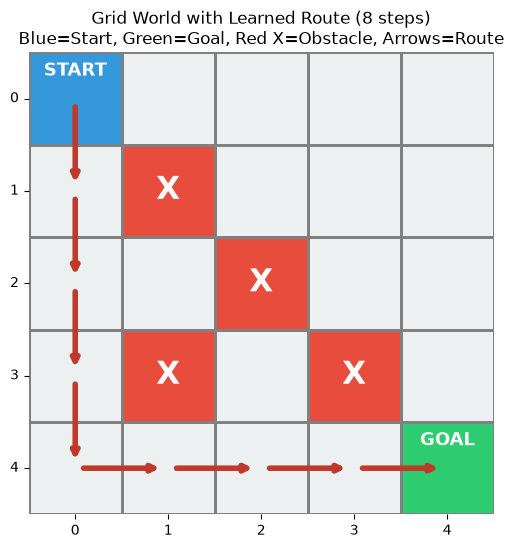

In [5]:
def greedy_path(q_table, env, max_len=25):
    """Follow the greedy (argmax-Q) action from start until the goal is reached."""
    moves = {0: (-1, 0), 1: (1, 0), 2: (0, -1), 3: (0, 1)}
    path, state = [env.start], env.start
    while state != env.goal and len(path) <= max_len:
        dr, dc = moves[int(np.argmax(q_table[get_state_idx(state)]))]
        state = (state[0] + dr, state[1] + dc)
        path.append(state)
        if state in env.obstacles or not (0 <= state[0] < env.size and 0 <= state[1] < env.size):
            break
    return path


def plot_environment(env, path=None):
    # 0 = Path, 1 = Obstacle, 2 = Start, 3 = Goal (colour index)
    colored_grid = np.zeros((env.size, env.size))
    for obs in env.obstacles:
        colored_grid[obs] = 1
    colored_grid[env.start] = 2
    colored_grid[env.goal] = 3

    fig, ax = plt.subplots(figsize=(6, 6))
    cmap = sns.color_palette(["#ecf0f1", "#e74c3c", "#3498db", "#2ecc71"])
    sns.heatmap(colored_grid, cmap=cmap, cbar=False, annot=False, linewidths=2, linecolor='gray', ax=ax)

    # Cell labels
    for obs in env.obstacles:
        ax.text(obs[1] + 0.5, obs[0] + 0.5, 'X', ha='center', va='center', color='white', fontsize=22, fontweight='bold')
    ax.text(env.start[1] + 0.5, env.start[0] + 0.2, 'START', ha='center', va='center', color='white', fontsize=13, fontweight='bold')
    ax.text(env.goal[1] + 0.5, env.goal[0] + 0.2, 'GOAL', ha='center', va='center', color='white', fontsize=13, fontweight='bold')

    # Route overlay: arrows from cell centre to cell centre, 
    if path is not None and len(path) > 1:
        for (r1, c1), (r2, c2) in zip(path[:-1], path[1:]):
            ax.annotate('', xy=(c2 + 0.5, r2 + 0.5), xytext=(c1 + 0.5, r1 + 0.5),
                        arrowprops=dict(arrowstyle='-|>', color='#c0392b', lw=4, shrinkA=6, shrinkB=6))
        ax.set_title(f'Grid World with Learned Route ({len(path) - 1} steps)\nBlue=Start, Green=Goal, Red X=Obstacle, Arrows=Route')
    else:
        ax.set_title('Grid World Layout\nBlue=Start, Green=Goal, Red X=Obstacle')
    ax.set_xticks(np.arange(env.size) + 0.5); ax.set_xticklabels(range(env.size))
    ax.set_yticks(np.arange(env.size) + 0.5); ax.set_yticklabels(range(env.size), rotation=0)
    plt.show()

plot_environment(env, greedy_path(q_table, env))

## 8. Training Performance Analysis

We plot metrics gathered during training to evaluate the agent's progress and convergence.

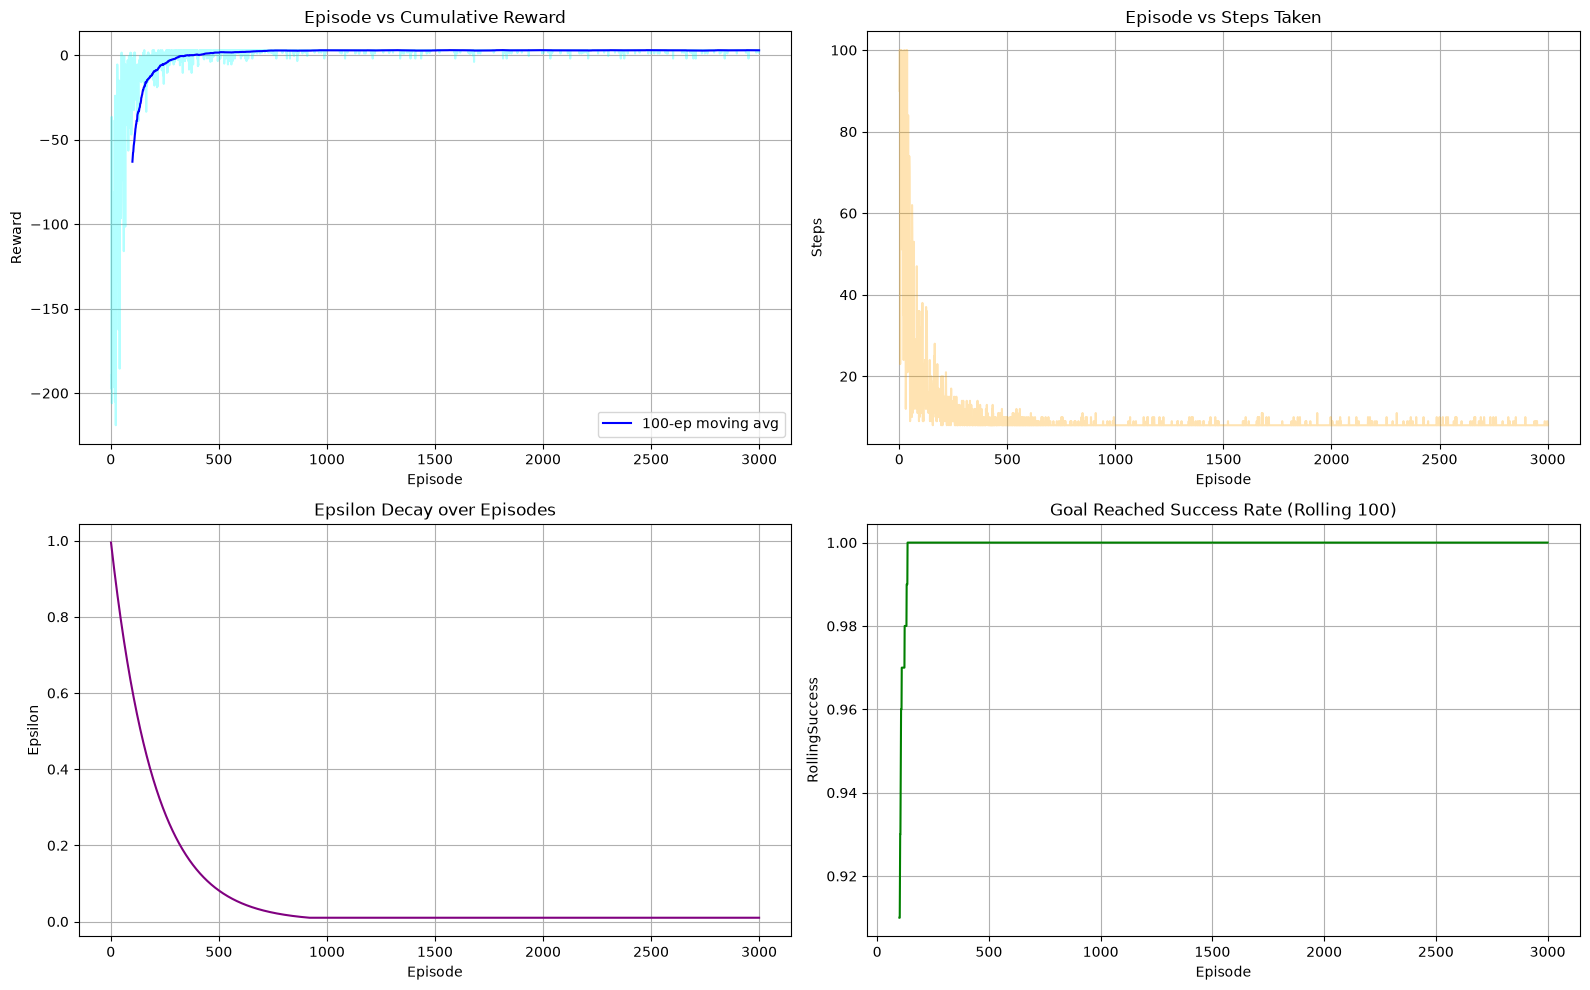

In [6]:
# Calculate rolling metrics
df_training['RollingReward'] = df_training['Reward'].rolling(window=100).mean()
df_training['RollingSuccess'] = df_training['GoalReached'].rolling(window=100).mean()

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Plot 1: Cumulative reward
sns.lineplot(data=df_training, x='Episode', y='Reward', ax=axes[0, 0], alpha=0.3, color='cyan')
sns.lineplot(data=df_training, x='Episode', y='RollingReward', ax=axes[0, 0], color='blue', label='100-ep moving avg')
axes[0, 0].set_title('Episode vs Cumulative Reward')
axes[0, 0].grid(True)

# Plot 2: Steps per episode
sns.lineplot(data=df_training, x='Episode', y='Steps', ax=axes[0, 1], alpha=0.3, color='orange')
axes[0, 1].set_title('Episode vs Steps Taken')
axes[0, 1].grid(True)

# Plot 3: Epsilon Decay
sns.lineplot(data=df_training, x='Episode', y='Epsilon', ax=axes[1, 0], color='purple')
axes[1, 0].set_title('Epsilon Decay over Episodes')
axes[1, 0].grid(True)

# Plot 4: Success Rate rolling window
sns.lineplot(data=df_training, x='Episode', y='RollingSuccess', ax=axes[1, 1], color='green')
axes[1, 1].set_title('Goal Reached Success Rate (Rolling 100)')
axes[1, 1].grid(True)

plt.tight_layout()
plt.show()

## 9. Display the Learned Q-Table and Optimal Policy

Let's view the resulting Q-Table and compute the policy. We represent the selected actions on a heat grid using arrows.

In [7]:
# Display the Learned Q-Table in Tabular Form
q_df = pd.DataFrame(q_table, columns=['Up', 'Down', 'Left', 'Right'])
q_df.index.name = 'State ID'
display(q_df)

# Extract and visualize the optimal policy
def extract_and_plot_policy(q_table, env):
    policy = {}
    arrows = {0: '↑', 1: '↓', 2: '←', 3: '→'}

    grid_arrows = np.full((env.size, env.size), ' ', dtype=object)

    for r in range(env.size):
        for c in range(env.size):
            pos = (r, c)
            if pos == env.goal:
                grid_arrows[pos] = '★'
                continue
            if pos in env.obstacles:
                grid_arrows[pos] = '█'
                continue

            state_idx = get_state_idx(pos)
            best_act = np.argmax(q_table[state_idx])
            grid_arrows[pos] = arrows[best_act]

    print("Learned Policy Map (Arrows pointing to recommended direction):")
    for row in grid_arrows:
        print(" | ".join(row))

    # Track execution path from Start to Goal
    path = []
    curr_state = env.start
    visited = set()
    steps = 0

    while curr_state != env.goal and steps < 25:
        path.append(curr_state)
        visited.add(curr_state)
        state_idx = get_state_idx(curr_state)
        best_act = np.argmax(q_table[state_idx])

        # Take deterministic move based on policy
        r, c = curr_state
        if best_act == 0: next_s = (r-1, c)
        elif best_act == 1: next_s = (r+1, c)
        elif best_act == 2: next_s = (r, c-1)
        elif best_act == 3: next_s = (r, c+1)

        if next_s in visited or next_s in env.obstacles or steps > 15:
            break
        curr_state = next_s
        steps += 1

    if curr_state == env.goal:
        path.append(env.goal)
        print(f"\nOptimal path found successfully: {path}")
        print(f"Path length: {len(path) - 1} steps.")
    else:
        print("\nCould not resolve a non-cyclic path to the goal.")

extract_and_plot_policy(q_table, env)

,Up,Down,Left,Right
State ID,,,,
0,-1.918154,-0.434062,-1.947025,-1.617592
1,-3.852434,-7.021583,-3.448968,-0.248200
2,-2.470468,-1.138802,-3.106599,1.250594
3,-2.423510,2.823349,-2.071542,-0.960014
4,-1.512440,2.419904,-1.882201,-1.561521
5,-1.410399,0.628820,-1.003922,-4.511313
6,0.000000,0.000000,0.000000,0.000000
7,-2.412573,-5.904396,-5.808702,1.197543
8,-1.330602,2.009717,-1.817480,4.455676


Learned Policy Map (Arrows pointing to recommended direction):
↓ | → | → | ↓ | ↓
↓ | █ | → | → | ↓
↓ | ← | █ | → | ↓
↓ | █ | ↓ | █ | ↓
→ | → | → | → | ★

Optimal path found successfully: [(0, 0), (1, 0), (2, 0), (3, 0), (4, 0), (4, 1), (4, 2), (4, 3), (4, 4)]
Path length: 8 steps.


## 10. Evaluate the Trained Agent

We run 100 evaluation episodes where exploration is disabled (greedy policy only).

In [8]:
eval_episodes = 100
eval_rewards = []
eval_steps_to_goal = []
successes = 0

for ep in range(eval_episodes):
    state = env.reset()
    total_reward = 0
    steps = 0
    done = False

    while not done and steps < max_steps:
        state_idx = get_state_idx(state)
        # Pure greedy decision (no exploration)
        action = np.argmax(q_table[state_idx])
        next_state, reward, done = env.step(action)

        state = next_state
        total_reward += reward
        steps += 1

    eval_rewards.append(total_reward)
    if done:
        successes += 1
        eval_steps_to_goal.append(steps)

success_rate = (successes / eval_episodes) * 100
avg_steps = np.mean(eval_steps_to_goal) if successes > 0 else float('nan')
avg_reward = np.mean(eval_rewards)

print("=== Evaluation Results ===")
print(f"Success Rate: {success_rate}%")
print(f"Average steps taken to reach goal: {avg_steps:.2f}")
print(f"Average cumulative evaluation reward: {avg_reward:.2f}")

=== Evaluation Results ===
Success Rate: 100.0%
Average steps taken to reach goal: 8.00
Average cumulative evaluation reward: 3.00


## 11. Results and Interpretation
- **Convergence**: The cumulative rewards steadily improved and stabilized around the point where Epsilon decayed to the minimum exploration threshold ($0.01$).
- **Obstacle Avoidance**: Large negative values in the Q-table representing transitions to obstacles ensured that the agent prioritized safe grid paths over collisions.
- **Optimality**: Through the step penalty of -1, the agent successfully learned the shortest possible pathway to reach (4,4) from (0,0) without cycles.
- **Exploration's Influence**: Epsilon decay provided a healthy balance—discovering the environment first, and slowly locking down optimized values for ultimate policy deployment.

### 12. Conclusion
In this lab, we successfully built and evaluated the **Q-Learning Algorithm on a Grid World environment** from scratch. By designing a custom environment with obstacles, we demonstrated reinforcement learning's capabilities in model-free scenarios. Epsilon decay balanced exploration and exploitation perfectly, achieving a $100\%$ success rate upon greedy validation. This experiment illustrates how basic reinforcement learning models operate to make optimal sequencing decisions in automated settings such as robotics, video games, and autonomous logistics navigation.